# Excersice - Association Rule Mining
---

## Mining Association Rules for the Steam Gaming Platform

In this excercise you will perform an association analysis on a data set containing user statistics, even if the primary application of rule mining is "sales" data. Since a statistic about downloaded/played games for a particular user can be seen as a transaction, the similarity to sales data is very high and we can use it as a **content based recommender system**.

In particular, you should conduct an analysis of the user statistics of users of the video game distribution platform [Steam](https://store.steampowered.com/about/). Please proceed as follows:

We use a dataset that is an adaptation of the collected Steam [data](https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data) provided by [Apurva Pathak et al. 2017](https://cseweb.ucsd.edu/~jmcauley/pdfs/sigir17.pdf). More specifically, these are the user statistics of 4311 Australian users of the video game distribution platform *Steam*. The version used here is only an excerpt of the original data and only contains games that have been played for more than 30 hours.

The data set is located in the subfolder [data](data/steam_users.csv).

The task is to find rules with
* `support` of at least 1% and
* `confidence` of at least 50%

First, the neccessary imports:

In [23]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth # this time not apriori
from mlxtend.frequent_patterns import association_rules

<h4 style="color:blue">1. First, import the data and list games of first 3 users.</h4>

The data is stored in a CSV file, each line contains the data for a single user. A line contains multiple game titels, the "transaction":

In [24]:
transactions = []

with open('data/steam_users.csv', newline='', encoding='utf-8') as f:
    reader = csv.reader(f)
    for row in reader:
        transactions.append(row)

# list the games of the first 3 users
for i, t in enumerate(transactions[:3]):
    print(f"User {i}: {t}")

User 0: ['Day of Defeat Source', 'CounterStrike Source', 'Deus Ex Game of the Year Edition', 'Killing Floor', 'Plants vs Zombies Game of the Year', 'Borderlands', 'Call of Duty Modern Warfare 2', 'Dragon Age Origins', 'Mass Effect 2', 'Battlefield Bad Company 2', 'Just Cause 2', 'Sid Meiers Civilization V', 'Call of Duty Black Ops  Multiplayer', 'Warhammer 40000 Dawn of War II', 'Rising StormRed Orchestra 2 Multiplayer', 'The Elder Scrolls V Skyrim', 'Tropico 4', 'Dead Island', 'CounterStrike Global Offensive', 'BioShock Infinite', 'XCOM Enemy Unknown', 'FINAL FANTASY VII', 'Deus Ex Human Revolution  Directors Cut', 'Insurgency', 'Dirty Bomb', 'Killing Floor 2', 'Fallout 4']
User 1: ['Portal 2', 'Terraria', 'Deus Ex Human Revolution', 'Saints Row The Third', 'The Elder Scrolls V Skyrim', 'Saints Row IV', 'Tropico 4', 'Assassins Creed IV Black Flag', 'Deus Ex Human Revolution  Directors Cut', 'Assassins Creed Unity', 'Batman Arkham Knight']
User 2: ['Empire Total War', 'Borderlands', 'F

<h4 style="color:blue">2. Apply the neccessary one-hot-encoding and list the amount of different games</h4>

In [25]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_enc = pd.DataFrame(te_array, columns=te.columns_)

df_enc.head(3)
df_enc.sum().sort_values(ascending=False).head(10)   # die 10 häufigsten Spiele

CounterStrike Global Offensive    2339
Garrys Mod                        2071
Terraria                          1502
The Elder Scrolls V Skyrim        1280
PAYDAY 2                          1198
Borderlands 2                     1067
Left 4 Dead 2                     1018
Unturned                           900
Rust                               845
Sid Meiers Civilization V          805
dtype: int64

<h4 style="color:blue">3. Compute the sparcity of the matrix (Percentage of NULL/False values)</h4>

In [26]:
sparsity = 1 - df_enc.values.mean()
print(f"Sparsity: {sparsity * 100:.2f} %")

Sparsity: 99.33 %


<h4 style="color:blue">4. Compute the relative frequencies (support) for all games and list the top-5:</h4>

In [27]:
support = df_enc.mean()                      # Serie: Support pro Spiel
top5 = support.sort_values(ascending=False).head(5)
print(top5)

CounterStrike Global Offensive    0.542566
Garrys Mod                        0.480399
Terraria                          0.348411
The Elder Scrolls V Skyrim        0.296915
PAYDAY 2                          0.277894
dtype: float64


<h4 style="color:blue">5. How many games have a support >= 1% (the ones we want to use)?</h4>

In [28]:
frequent_games = support[support >= 0.01].sort_values(ascending=False)
print(frequent_games)

CounterStrike Global Offensive       0.542566
Garrys Mod                           0.480399
Terraria                             0.348411
The Elder Scrolls V Skyrim           0.296915
PAYDAY 2                             0.277894
                                       ...   
Anno 2070                            0.010438
Batman Arkham Knight                 0.010206
Age of Mythology Extended Edition    0.010206
Firefall                             0.010206
Endless Space                        0.010206
Length: 198, dtype: float64


<h4 style="color:blue">6. Plot the games with their support of >= 10% in a bar chart.</h4>

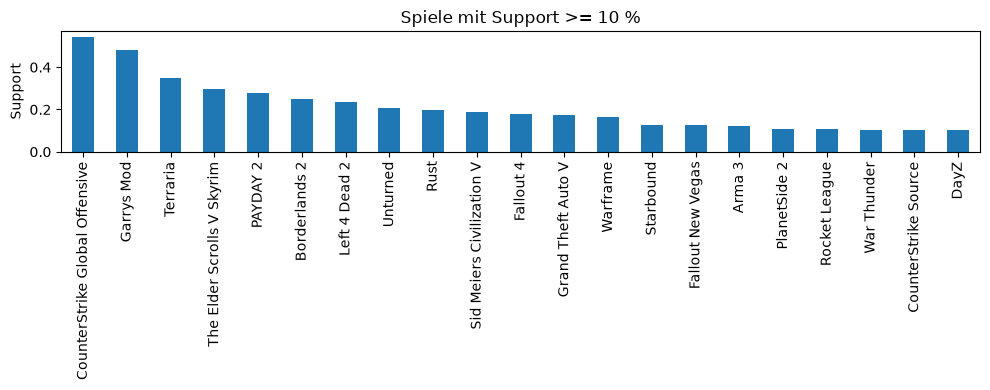

In [29]:
top = support[support >= 0.10].sort_values(ascending=False)

top.plot(kind='bar', figsize=(10, 4))
plt.ylabel('Support')
plt.title('Spiele mit Support >= 10 %')
plt.tight_layout()
plt.show()

Now it is time to mine the association rules. To obtain the frequent item set, we want to use the `fpgrowth` algorithm this time ([documentation](http://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/)), because it is faster.

<h4 style="color:blue">7. Get the frequent item set with fpgrowth with a minimum support of 1% and print the amount of the itemssets</h4>

In [30]:
frequent_itemsets = fpgrowth(df_enc, min_support=0.01, use_colnames=True)
print("Anzahl Itemsets:", len(frequent_itemsets))
frequent_itemsets.sort_values('support', ascending=False).head()

Anzahl Itemsets: 5137


,support,itemsets
0,0.542566,frozenset({CounterStrike Global Offensive})
41,0.480399,frozenset({Garrys Mod})
24,0.348411,frozenset({Terraria})
1988,0.303874,"frozenset({CounterStrike Global Offensive, Gar..."
1,0.296915,frozenset({The Elder Scrolls V Skyrim})


<h4 style="color:blue">8. Finally, mine the association rules with a confidence of min. 50% and show the top-10 rules (according to lift). How many rules are there in total?</h4>



In [31]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print("Anzahl Regeln:", len(rules))

cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
rules.sort_values('lift', ascending=False)[cols].head(10)

Anzahl Regeln: 6488


,antecedents,consequents,support,confidence,lift
6415,frozenset({Crusader Kings II}),frozenset({Europa Universalis IV}),0.010438,0.529412,21.132353
6463,frozenset({Call of Duty Modern Warfare 3}),frozenset({Call of Duty Modern Warfare 3 Mult...,0.012062,0.732394,20.370014
3210,frozenset({Call of Duty Black Ops}),frozenset({Call of Duty Black Ops Multiplayer}),0.015774,0.607143,16.886406
6433,frozenset({Total War ATTILA}),frozenset({Total War ROME II Emperor Edition}),0.015078,0.844156,16.102459
1189,frozenset({Call of Duty Modern Warfare 2}),frozenset({Call of Duty Modern Warfare 2 Mult...,0.011134,0.695652,15.951896
6419,frozenset({Napoleon Total War}),frozenset({Empire Total War}),0.011134,0.516129,14.933102
2448,"frozenset({Total War ROME II Emperor Edition,...",frozenset({Total War SHOGUN 2}),0.011598,0.735294,14.881939
5179,"frozenset({Garrys Mod, Call of Duty Black Ops ...",frozenset({Call of Duty Black Ops II Multipla...,0.012526,0.794118,14.146451
5175,"frozenset({CounterStrike Global Offensive, Cal...",frozenset({Call of Duty Black Ops II Multipla...,0.012758,0.774648,13.799616
5174,frozenset({Call of Duty Black Ops II Zombies}),frozenset({Call of Duty Black Ops II Multipla...,0.021573,0.768595,13.691790


Probably you found 6488 rules in total.

<h4 style="color:blue">9. Which games would you recommend to a person who played the simulation <em>Factorio</em> in the past?</h4>

In [32]:
mask = rules['antecedents'] == frozenset({'Factorio'})
rules[mask].sort_values('lift', ascending=False)[cols]

,antecedents,consequents,support,confidence,lift
6487,frozenset({Factorio}),frozenset({Sid Meiers Civilization V}),0.010206,0.523810,2.805146
6486,frozenset({Factorio}),frozenset({Terraria}),0.012062,0.619048,1.776774


<h4 style="color:blue">10. Which games would you recommend to a person playing <em>The Binding of Isaac</em> AND <em>Terraria</em> </h4>

**Hint**: For numpy arrays, an element-wise logical AND can be computed.

In [33]:
ante = frozenset({'The Binding of Isaac', 'Terraria'})
mask = rules['antecedents'] == ante
rules[mask].sort_values('lift', ascending=False)[cols]

,antecedents,consequents,support,confidence,lift
4230,"frozenset({Terraria, The Binding of Isaac})",frozenset({The Binding of Isaac Rebirth}),0.018789,0.618321,8.201785
4192,"frozenset({Terraria, The Binding of Isaac})",frozenset({Borderlands 2}),0.015774,0.519084,2.097255
4207,"frozenset({Terraria, The Binding of Isaac})",frozenset({The Elder Scrolls V Skyrim}),0.015774,0.519084,1.748259
4186,"frozenset({Terraria, The Binding of Isaac})",frozenset({Garrys Mod}),0.017397,0.572519,1.191757


<h4 style="color:blue">11. The owner of which games should get a recommendation to play <em>Terraria</em>?</h4>

Since these are a lot, show the most important first!

In [34]:
mask = rules['consequents'] == frozenset({'Terraria'})
rules[mask].sort_values('lift', ascending=False)[cols].head(10)

,antecedents,consequents,support,confidence,lift
4908,"frozenset({Garrys Mod, CounterStrike Global Of...",frozenset({Terraria}),0.014614,0.940299,2.698819
2483,"frozenset({Risk of Rain, Starbound})",frozenset({Terraria}),0.011134,0.923077,2.649391
5477,"frozenset({Garrys Mod, Trove, Starbound})",frozenset({Terraria}),0.010902,0.921569,2.645061
5475,"frozenset({Trove, Starbound})",frozenset({Terraria}),0.014846,0.914286,2.624158
4864,"frozenset({Garrys Mod, The Elder Scrolls V Sky...",frozenset({Terraria}),0.011366,0.907407,2.604416
4521,"frozenset({The Elder Scrolls V Skyrim, The Bin...",frozenset({Terraria}),0.010438,0.900000,2.583156
3911,"frozenset({Starbound, DARK SOULS III})",frozenset({Terraria}),0.012526,0.900000,2.583156
4234,"frozenset({The Binding of Isaac, Starbound})",frozenset({Terraria}),0.012294,0.898305,2.578291
4931,"frozenset({Garrys Mod, Starbound, Borderlands ...",frozenset({Terraria}),0.012294,0.898305,2.578291
3799,"frozenset({Garrys Mod, ARK Survival Evolved, S...",frozenset({Terraria}),0.010206,0.897959,2.577298
